# 03 — Treatment vs Exposure: ITT vs CACE (Step 4)

**Two different things:**
- `treatment` (Z) = user was **randomly assigned** to see ads → random ✅
- `exposure` (D) = user **actually saw** an ad → not random ❌ (depends on the auction, how active the user is, site visits)

**Question:** "What is the effect of showing an ad on visits?" There are three possible answers. Only two are correct:

| Approach | Comparison | Correct? |
|---|---|---|
| Naive | Exposed vs not-exposed users | ❌ Selection bias |
| **ITT** | Assigned treatment vs assigned control | ✅ Unbiased (random): the effect of the ad *campaign* |
| **CACE** | ITT / exposure rate | ✅ The effect on users who actually saw the ad |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_criteo, FEATURES
from src.stats_tests import (itt_effect, wald_cace, bootstrap_cace,
                             complier_outcome_means, balance_table)

FIG = Path.cwd().parent / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
df = load_criteo()
Z, D = df.treatment.values, df.exposure.values
print(df.shape)

(1397959, 16)


## 4.1 Compliance structure
Exposure is 0 in control → **one-sided non-compliance**. The treatment group holds two kinds of users: **compliers** (saw the ad) and **never-takers** (did not).

In [2]:
ct = pd.crosstab(df.treatment.map({0: "control", 1: "treatment"}),
                 df.exposure.map({0: "not exposed", 1: "exposed"}), margins=True)
ct

exposure,exposed,not exposed,All
treatment,,,
control,0,209220,209220
treatment,42803,1145936,1188739
All,42803,1355156,1397959


In [3]:
p = D[Z == 1].mean()
print(f"Compliance (first stage) = P(exposed | treatment) - P(exposed | control) = {p:.4%} - {D[Z==0].mean():.4%}")

Compliance (first stage) = P(exposed | treatment) - P(exposed | control) = 3.6007% - 0.0000%


## 4.2 ❌ Wrong approach: naive comparison

Two naive comparisons people often make:
1. Inside the treatment group: **exposed vs not exposed**
2. **Exposed vs the whole control group**

In [4]:
rows = {}
for m in ["visit", "conversion"]:
    y = df[m].values
    exp_t = y[(Z == 1) & (D == 1)].mean()
    unexp_t = y[(Z == 1) & (D == 0)].mean()
    ctrl = y[Z == 0].mean()
    rows[m] = {"exposed (T)": exp_t, "not exposed (T)": unexp_t, "control": ctrl,
               "naive 1: exposed − not exposed": exp_t - unexp_t,
               "naive 2: exposed − control": exp_t - ctrl}
naive = pd.DataFrame(rows)
naive

,visit,conversion
exposed (T),0.41834,0.05586
not exposed (T),0.03505,0.00123
control,0.03818,0.00196
naive 1: exposed − not exposed,0.38329,0.05463
naive 2: exposed − control,0.38015,0.05390


**Red flag:** the visit rate of *not exposed* treatment users is even lower than control. If exposure were random,
the two would be equal (neither group saw an ad). So exposed and unexposed users are **different to begin with**.

Confirm with the features: SMD of exposed vs not exposed (in Step 3, the maximum SMD for treatment vs control was 0.049):

In [5]:
tg = df[df.treatment == 1]
bal_exp = balance_table(tg, FEATURES, treatment_col="exposure")
bal_rand = balance_table(df, FEATURES, treatment_col="treatment")
cmp = pd.DataFrame({"|SMD| exposed vs not (T)": bal_exp.abs_smd,
                    "|SMD| treatment vs control": bal_rand.abs_smd}).sort_values("|SMD| exposed vs not (T)", ascending=False)
cmp

,|SMD| exposed vs not (T),|SMD| treatment vs control
feature,,
f3,1.46198,0.04914
f6,1.38244,0.04173
f8,1.01970,0.02054
f9,0.89074,0.02217
f0,0.85354,0.00407
f5,0.64163,0.02973
f7,0.59119,0.01885
f4,0.45678,0.00914
f1,0.43402,0.02635


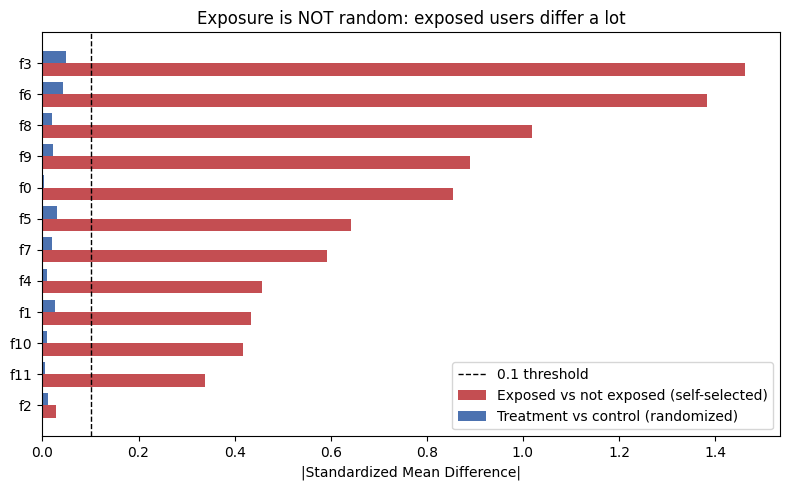

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(cmp))
ax.barh(y_pos + 0.2, cmp.iloc[:, 0], height=0.4, color="#C44E52", label="Exposed vs not exposed (self-selected)")
ax.barh(y_pos - 0.2, cmp.iloc[:, 1], height=0.4, color="#4C72B0", label="Treatment vs control (randomized)")
ax.axvline(0.1, color="black", ls="--", lw=1, label="0.1 threshold")
ax.set_yticks(y_pos, cmp.index)
ax.invert_yaxis()
ax.set_xlabel("|Standardized Mean Difference|")
ax.set_title("Exposure is NOT random: exposed users differ a lot")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "03_exposure_imbalance.png", dpi=110)
plt.show()

## 4.3 ✅ Correct approach 1: ITT (Intent-to-Treat)

Compare by **random assignment** only, whether or not the ad was shown. Randomization makes this unbiased.
Business meaning: *"the effect of running (assigning) the campaign"*.

In [7]:
itt = pd.DataFrame({m: itt_effect(df.loc[Z == 1, m].values, df.loc[Z == 0, m].values)
                    for m in ["visit", "conversion"]}).T
itt

,rate_t,rate_c,effect,se,ci_low,ci_high,rel_lift,p_value
visit,0.04885,0.03818,0.01067,0.00046,0.00976,0.01157,0.27931,0.00000
conversion,0.00320,0.00196,0.00123,0.00011,0.00102,0.00145,0.62684,0.00000


## 4.4 ✅ Correct approach 2: CACE (Wald / IV estimator)

The ITT is "diluted": 96% of treatment users never saw the ad, so their effect is 0. Assuming:
- **Exclusion restriction:** being assigned does nothing unless the ad is actually shown
- **Monotonicity:** nobody in control saw the ad (confirmed in the data: 0%)

then: $$CACE = \frac{ITT_{visit}}{ITT_{exposure}} = \frac{\text{effect of assignment on visit}}{\text{effect of assignment on exposure}}$$

Here `treatment` is an **instrument**: it is random, and it changes exposure.

In [8]:
cace = pd.DataFrame({m: wald_cace(df[m].values, D, Z) for m in ["visit", "conversion"]}).T
cace

,itt_y,itt_d,cace,se,ci_low,ci_high,first_stage_F
visit,0.01067,0.03601,0.29620,0.01274,0.27123,0.32118,"44,401.74025"
conversion,0.00123,0.03601,0.03420,0.00304,0.02824,0.04016,"44,401.74025"


### Confirm with the bootstrap (2,000 resamples)

In [9]:
boot = {m: bootstrap_cace(df[m].values, D, Z, n_boot=2000) for m in ["visit", "conversion"]}
bt = pd.DataFrame({m: {"ITT delta CI": f"[{itt.loc[m,'ci_low']:.5f}, {itt.loc[m,'ci_high']:.5f}]",
                       "ITT bootstrap CI": f"[{b['itt_ci'][0]:.5f}, {b['itt_ci'][1]:.5f}]",
                       "CACE delta CI": f"[{cace.loc[m,'ci_low']:.4f}, {cace.loc[m,'ci_high']:.4f}]",
                       "CACE bootstrap CI": f"[{b['cace_ci'][0]:.4f}, {b['cace_ci'][1]:.4f}]"}
                   for m, b in boot.items()}).T
bt

,ITT delta CI,ITT bootstrap CI,CACE delta CI,CACE bootstrap CI
visit,"[0.00976, 0.01157]","[0.00977, 0.01156]","[0.2712, 0.3212]","[0.2712, 0.3209]"
conversion,"[0.00102, 0.00145]","[0.00101, 0.00144]","[0.0282, 0.0402]","[0.0281, 0.0399]"


## 4.5 How large is the selection bias? (Complier decomposition)

Because of randomization, the never-taker share and their visit rate are the same in both groups. That lets us estimate
**how often exposed users would have visited without the ad** (the counterfactual):

$$\bar Y_C = p\cdot Y_0^{compliers} + (1-p)\cdot Y^{never} \Rightarrow Y_0^{compliers} = \frac{\bar Y_C - (1-p)\,Y^{never}}{p}$$

In [10]:
dec = pd.DataFrame({m: complier_outcome_means(df[m].values, D, Z) for m in ["visit", "conversion"]}).T
dec["naive (exposed − not exposed)"] = naive.loc["naive 1: exposed − not exposed"]
dec["selection bias"] = dec["naive (exposed − not exposed)"] - dec["cace"]
dec

,complier_share,y_never_takers,y1_compliers,y0_compliers,cace,naive (exposed − not exposed),selection bias
visit,0.03601,0.03505,0.41834,0.12213,0.29620,0.38329,0.08708
conversion,0.03601,0.00123,0.05586,0.02166,0.03420,0.05463,0.02043


In [11]:
v = dec.loc["visit"]
print(f"Visit rate of exposed users (with the ad):          {v.y1_compliers:.2%}")
print(f"Same users if the ad were NOT shown (counterfactual): {v.y0_compliers:.2%}")
print(f"Visit rate of never-takers:                          {v.y_never_takers:.2%}")
print(f"=> True effect of the ad (CACE):                     {v.cace*100:+.1f} pp")
print(f"=> Naive estimate:                                   {v['naive (exposed − not exposed)']*100:+.1f} pp")
print(f"=> Selection bias:                                   {v['selection bias']*100:+.1f} pp "
      f"({v['selection bias']/v['naive (exposed − not exposed)']:.0%} of naive estimate)")

Visit rate of exposed users (with the ad):          41.83%
Same users if the ad were NOT shown (counterfactual): 12.21%
Visit rate of never-takers:                          3.50%
=> True effect of the ad (CACE):                     +29.6 pp
=> Naive estimate:                                   +38.3 pp
=> Selection bias:                                   +8.7 pp (23% of naive estimate)


## 4.6 Summary chart

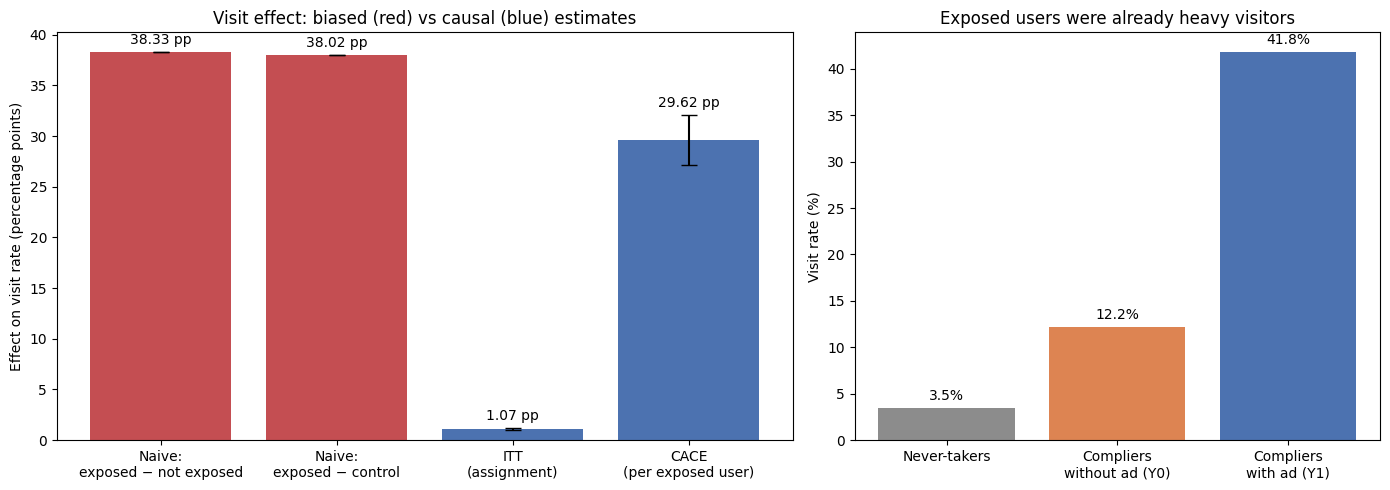

In [12]:
m = "visit"
labels = ["Naive:\nexposed − not exposed", "Naive:\nexposed − control", "ITT\n(assignment)", "CACE\n(per exposed user)"]
vals = [naive.loc["naive 1: exposed − not exposed", m], naive.loc["naive 2: exposed − control", m],
        itt.loc[m, "effect"], cace.loc[m, "cace"]]
errs = [0, 0, itt.loc[m, "effect"] - itt.loc[m, "ci_low"], cace.loc[m, "cace"] - cace.loc[m, "ci_low"]]
colors = ["#C44E52", "#C44E52", "#4C72B0", "#4C72B0"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
bars = ax.bar(labels, np.array(vals) * 100, yerr=np.array(errs) * 100, color=colors, capsize=6)
for b, val, e in zip(bars, vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, (val + e) * 100 + 0.8, f"{val*100:.2f} pp", ha="center", fontsize=10)
ax.set_ylabel("Effect on visit rate (percentage points)")
ax.set_title("Visit effect: biased (red) vs causal (blue) estimates")

ax = axes[1]
v = dec.loc["visit"]
bars = ax.bar(["Never-takers", "Compliers\nwithout ad (Y0)", "Compliers\nwith ad (Y1)"],
              [v.y_never_takers * 100, v.y0_compliers * 100, v.y1_compliers * 100],
              color=["#8C8C8C", "#DD8452", "#4C72B0"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center")
ax.set_ylabel("Visit rate (%)")
ax.set_title("Exposed users were already heavy visitors")
fig.tight_layout()
fig.savefig(FIG / "03_itt_vs_cace.png", dpi=110)
plt.show()

## Summary

In [13]:
for m in ["visit", "conversion"]:
    print(f"{m.upper()}")
    print(f"  ITT  = {itt.loc[m,'effect']*100:+.3f} pp  95% CI [{itt.loc[m,'ci_low']*100:.3f}, {itt.loc[m,'ci_high']*100:.3f}]  (rel {itt.loc[m,'rel_lift']:+.1%})")
    print(f"  CACE = {cace.loc[m,'cace']*100:+.2f} pp  95% CI [{cace.loc[m,'ci_low']*100:.2f}, {cace.loc[m,'ci_high']*100:.2f}]")
    print(f"  Naive (exposed − not exposed) = {naive.loc['naive 1: exposed − not exposed', m]*100:+.2f} pp")
print(f"\nFirst-stage F = {cace.loc['visit','first_stage_F']:,.0f} (>> 10, strong instrument)")

VISIT
  ITT  = +1.067 pp  95% CI [0.976, 1.157]  (rel +27.9%)
  CACE = +29.62 pp  95% CI [27.12, 32.12]
  Naive (exposed − not exposed) = +38.33 pp
CONVERSION
  ITT  = +0.123 pp  95% CI [0.102, 0.145]  (rel +62.7%)
  CACE = +3.42 pp  95% CI [2.82, 4.02]
  Naive (exposed − not exposed) = +5.46 pp

First-stage F = 44,402 (>> 10, strong instrument)


## Key takeaways (Step 4)

1. **Exposure is not random.** Exposed vs not-exposed users reach |SMD| = 1.46 (11 of 12 features above 0.1),
   while treatment vs control peaked at 0.049. The ad was shown mostly to users who were already active.
2. **ITT (unbiased, campaign level):** visit +1.07 pp [0.98, 1.16] (+28%), conversion +0.12 pp [0.10, 0.14] (+63%).
   That is ~10.7 extra visits per 1,000 *assigned* users.
3. **CACE (per exposed user):** visit **+29.6 pp** [27.1, 32.1], conversion +3.4 pp [2.8, 4.0].
   Delta-method and bootstrap CIs are almost identical. First-stage F = 44,402, so the instrument is very strong.
4. **The naive estimate is 38.3 pp, 8.7 pp (23%) too high.** That extra part is selection bias, not the ad's effect.
   The bias is even larger for conversion: naive 5.5 pp vs CACE 3.4 pp (37% inflated).
5. **Counterfactual:** exposed users would have visited at 12.2% even *without* the ad, never-takers at only 3.5%.
   They were 3.5× more active. The ad moved their visit rate from 12.2% to 41.8%.

**Assumptions / caveats**
- CACE is the effect on **compliers** (users who can be reached by the ad), not on all users. Never-takers are different
  (less active) people and may respond differently, so CACE should not be extrapolated to "what if we showed everyone".
- Exclusion restriction assumed: assignment alone (without seeing the ad) has no effect on visits.

**What this means for ROI (Step 9):** break-even is 10 pp (₹0.50 / ₹5).
- If the cost is paid for every *assigned* user → effect 1.07 pp < 10 pp → **loss**.
- If the cost is paid only per *impression* (ad shown) → effect 29.6 pp > 10 pp → **profit**.
Real ad buying (CPM) charges per impression, so the CACE view is the more realistic one for Step 9.